# Lab #6: Keras MLP for Regression - Diabetes Progression Predictor

This notebook builds a Multi-Layer Perceptron (MLP) using TensorFlow/Keras to solve a **regression** problem: predicting a numeric value (disease progression score) instead of a class label. It's fully application-oriented — run the notebook top to bottom and it loads its own dataset, trains the model, and predicts on a real sample at the end.

### Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

tf.__version__

'2.21.0'

## Part 0 - Loading the Dataset

We use the **Diabetes dataset**, built directly into scikit-learn (no download needed). It contains 442 patient records with 10 baseline health measurements (age, BMI, blood pressure, blood serum levels, etc.), and the target is a **continuous number** measuring disease progression one year after baseline — a real regression problem, not a category.

In [2]:
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['disease_progression'] = y

print('Number of samples :', X.shape[0])
print('Number of features:', X.shape[1])
print('Feature names     :', feature_names)
print('Target range      : {:.1f} to {:.1f}'.format(y.min(), y.max()))
df.head()

Number of samples : 442
Number of features: 10
Feature names     : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target range      : 25.0 to 346.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## Part 1 - Data Preprocessing

### Checking for missing values

In [3]:
print('Missing values:', df.isnull().sum().sum())
# The sklearn Diabetes dataset is already clean

Missing values: 0


### Train/test split and feature scaling

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Feature scaling matters for MLPs so all 10 inputs are on a comparable scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print('Training samples:', X_train.shape[0])
print('Test samples    :', X_test.shape[0])

Training samples: 353
Test samples    : 89


## Part 2 - Building the MLP

For regression, the architecture looks almost identical to a classification MLP, except the **output layer** has just **1 neuron with no activation function (linear output)**, since we want a raw numeric prediction rather than a class probability.

### Initialising the model

In [5]:
mlp = Sequential()

### Input Layer + First Hidden Layer

In [6]:
mlp.add(Dense(units=16, activation='relu', input_shape=(X_train.shape[1],)))

c:\Users\rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Second Hidden Layer

In [7]:
mlp.add(Dense(units=8, activation='relu'))

### Output Layer (Regression)

In [8]:
mlp.add(Dense(units=1))  # No activation = linear output, suited for regression

In [9]:
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

## Part 3 - Training the MLP

### Compiling the model

In [10]:
mlp.compile(optimizer='adam', loss='mse', metrics=['mae'])
# Loss: Mean Squared Error (MSE) - standard loss for regression
# Metric: Mean Absolute Error (MAE) - easier to interpret, same units as the target

### Training the model

In [11]:
history = mlp.fit(X_train, y_train,
                  validation_split=0.1,
                  epochs=100,
                  batch_size=16,
                  verbose=1)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 30012.7832 - mae: 154.5571 - val_loss: 27543.9395 - val_mae: 147.6605
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29964.1270 - mae: 154.3895 - val_loss: 27496.7246 - val_mae: 147.4845
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29921.6523 - mae: 154.2375 - val_loss: 27445.3164 - val_mae: 147.2885
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29875.3086 - mae: 154.0595 - val_loss: 27385.8750 - val_mae: 147.0546
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29819.6660 - mae: 153.8421 - val_loss: 27315.3652 - val_mae: 146.7714
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29752.6836 - mae: 153.5797 - val_loss: 27226.0234 - val_mae: 146.4082
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29664.7168 - mae: 153.2391 - val_loss: 27122.2773 - val_mae: 145.9866
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29559.6465 - mae: 152.8153 - val_loss

### Plotting Training vs Validation Loss

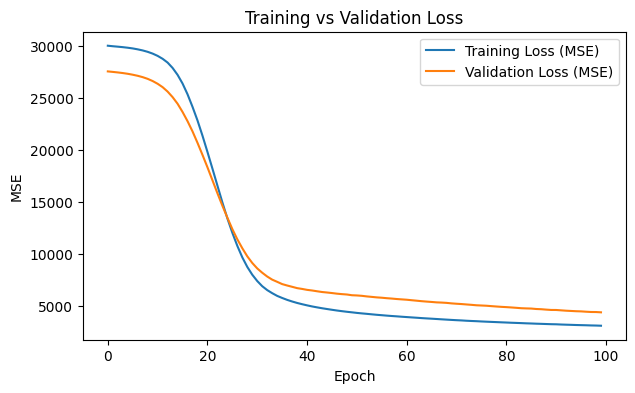

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

## Part 4 - Evaluating the Model

In [13]:
y_pred = mlp.predict(X_test, verbose=0).flatten()

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Test MSE  : {mse:.2f}')
print(f'Test RMSE : {rmse:.2f}')
print(f'Test MAE  : {mae:.2f}')
print(f'Test R2   : {r2:.4f}')

Test MSE  : 3424.43
Test RMSE : 58.52
Test MAE  : 46.34
Test R2   : 0.3537


### Actual vs Predicted Plot

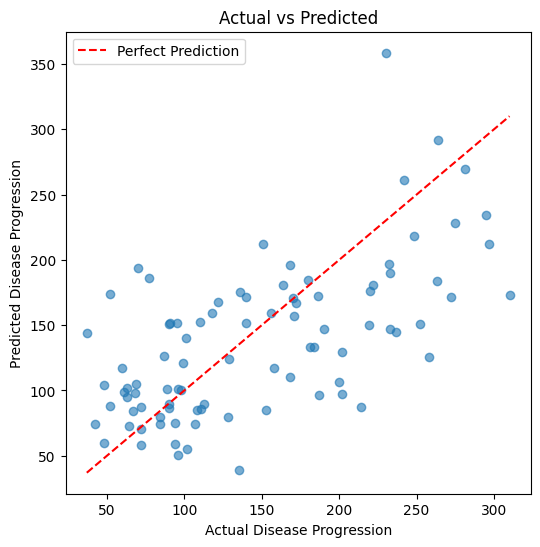

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Disease Progression')
plt.ylabel('Predicted Disease Progression')
plt.title('Actual vs Predicted')
plt.legend()
plt.show()

## Part 5 - Making a Single Prediction

This is the application-oriented step: pick one real patient's data from the test set, feed it through the trained model, and compare the predicted disease progression score against the actual value.

In [15]:
sample_index = 0
sample = X_test[sample_index].reshape(1, -1)

predicted_value = mlp.predict(sample, verbose=0)[0][0]
actual_value = y_test[sample_index]

print('Predicted disease progression score:', round(predicted_value, 2))
print('Actual disease progression score   :', round(actual_value, 2))
print('Difference                         :', round(abs(predicted_value - actual_value), 2))

Predicted disease progression score: 150.18
Actual disease progression score   : 219.0
Difference                         : 68.82


In [16]:
my_index = 10  # <-- change this to any index between 0 and len(X_test)-1

my_sample = X_test[my_index].reshape(1, -1)
my_prediction = mlp.predict(my_sample, verbose=0)[0][0]
my_actual = y_test[my_index]

print('Predicted:', round(my_prediction, 2))
print('Actual   :', round(my_actual, 2))

Predicted: 75.34
Actual   : 94.0
